<a href="https://colab.research.google.com/github/AK888-hp/ML-II_Lab/blob/main/FindS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = {
    "Age_Group": [
        "Young", "Adult", "Senior", "Young", "Adult",
        "Senior", "Young", "Adult", "Senior", "Young",
        "Adult", "Senior"
    ],

    "Income": [
        "Low", "High", "Medium", "Medium", "High",
        "Low", "High", "Medium", "High", "Low",
        "Medium", "Low"
    ],

    "Device": [
        "Mobile", "Laptop", "Mobile", "Laptop", "Laptop",
        "Mobile", "Mobile", "Laptop", "Mobile", "Mobile",
        "Laptop", "Laptop"
    ],

    "Browsing_Time": [
        "Short", "Long", "Long", "Long", "Short",
        "Short", "Long", "Long", "Long", "Short",
        "Short", "Long"
    ],

    "Previous_Purchase": [
        "No", "Yes", "Yes", "No", "Yes",
        "No", "Yes", "No", "Yes", "No",
        "Yes", "No"
    ],

    "Buy": [
        "No", "Yes", "Yes", "Yes", "Yes",
        "No", "Yes", "No", "Yes", "No",
        "Yes", "No"
    ]
}


In [ ]:
df = pd.DataFrame(data)

print("Dataset:")
print(df)


Dataset:
   Age_Group  Income  Device Browsing_Time Previous_Purchase  Buy
0      Young     Low  Mobile         Short                No   No
1      Adult    High  Laptop          Long               Yes  Yes
2     Senior  Medium  Mobile          Long               Yes  Yes
3      Young  Medium  Laptop          Long                No  Yes
4      Adult    High  Laptop         Short               Yes  Yes
5     Senior     Low  Mobile         Short                No   No
6      Young    High  Mobile          Long               Yes  Yes
7      Adult  Medium  Laptop          Long                No   No
8     Senior    High  Mobile          Long               Yes  Yes
9      Young     Low  Mobile         Short                No   No
10     Adult  Medium  Laptop         Short               Yes  Yes
11    Senior     Low  Laptop          Long                No   No


In [ ]:
def find_s(data, target_column):

    attributes = [
        col for col in data.columns
        if col != target_column
    ]

    # Most specific hypothesis
    hypothesis = ["0"] * len(attributes)

    # Store hypothesis after every positive example
    hypothesis_history = []

    for index, row in data.iterrows():

        # Find-S considers only positive examples
        if row[target_column] == "Yes":

            for i, attribute in enumerate(attributes):

                if hypothesis[i] == "0":
                    hypothesis[i] = row[attribute]

                elif hypothesis[i] != row[attribute]:
                    hypothesis[i] = "?"

            hypothesis_history.append(
                hypothesis.copy()
            )

            print(
                f"Positive Example {index + 1}: "
                f"{hypothesis}"
            )

    return attributes, hypothesis, hypothesis_history

In [ ]:
attributes, final_hypothesis, history = find_s(
    df, "Buy"
)

print("\nFinal Hypothesis:")
print(final_hypothesis)


Positive Example 2: ['Adult', 'High', 'Laptop', 'Long', 'Yes']
Positive Example 3: ['?', '?', '?', 'Long', 'Yes']
Positive Example 4: ['?', '?', '?', 'Long', '?']
Positive Example 5: ['?', '?', '?', '?', '?']
Positive Example 7: ['?', '?', '?', '?', '?']
Positive Example 9: ['?', '?', '?', '?', '?']
Positive Example 11: ['?', '?', '?', '?', '?']

Final Hypothesis:
['?', '?', '?', '?', '?']


In [ ]:
all_hypotheses = [["0"] * len(attributes)] + history

# Create labels H0, H1, H2, ...
hypothesis_labels = [
    f"H{i}" for i in range(len(all_hypotheses))
]

# Count attributes of each type
unused_counts = []
specific_counts = []
generalized_counts = []

for hypothesis in all_hypotheses:

    unused = hypothesis.count("0")
    generalized = hypothesis.count("?")
    specific = len(hypothesis) - unused - generalized

    unused_counts.append(unused)
    specific_counts.append(specific)
    generalized_counts.append(generalized)

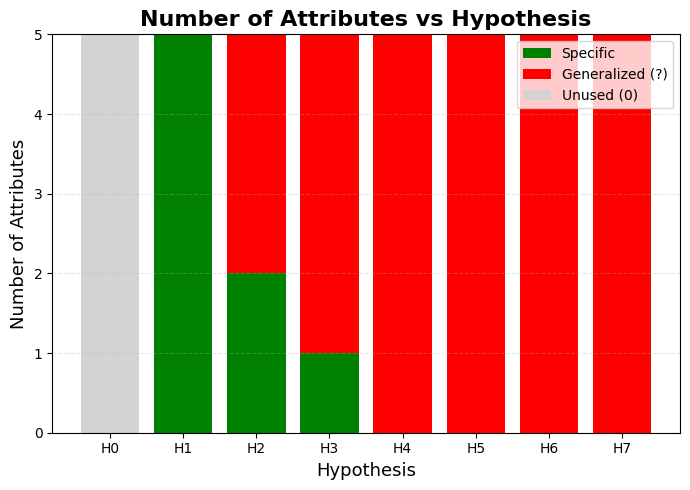

In [ ]:
plt.figure(figsize=(7, 5))

# Specific attributes
plt.bar(
    hypothesis_labels,
    specific_counts,
    color="green",
    label="Specific"
)

# Generalized attributes
plt.bar(
    hypothesis_labels,
    generalized_counts,
    bottom=specific_counts,
    color="red",
    label="Generalized (?)"
)

# Unused attributes
bottom_unused = [
    specific_counts[i] + generalized_counts[i]
    for i in range(len(hypothesis_labels))
]

plt.bar(
    hypothesis_labels,
    unused_counts,
    bottom=bottom_unused,
    color="lightgray",
    label="Unused (0)"
)
plt.title(
    "Number of Attributes vs Hypothesis",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Hypothesis",
    fontsize=13
)

plt.ylabel(
    "Number of Attributes",
    fontsize=13
)

plt.legend()

# Y-axis should represent number of attributes
plt.yticks(range(0, len(attributes) + 1))

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1710/3793186327.py:9: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  history_numeric = history_df.applymap(


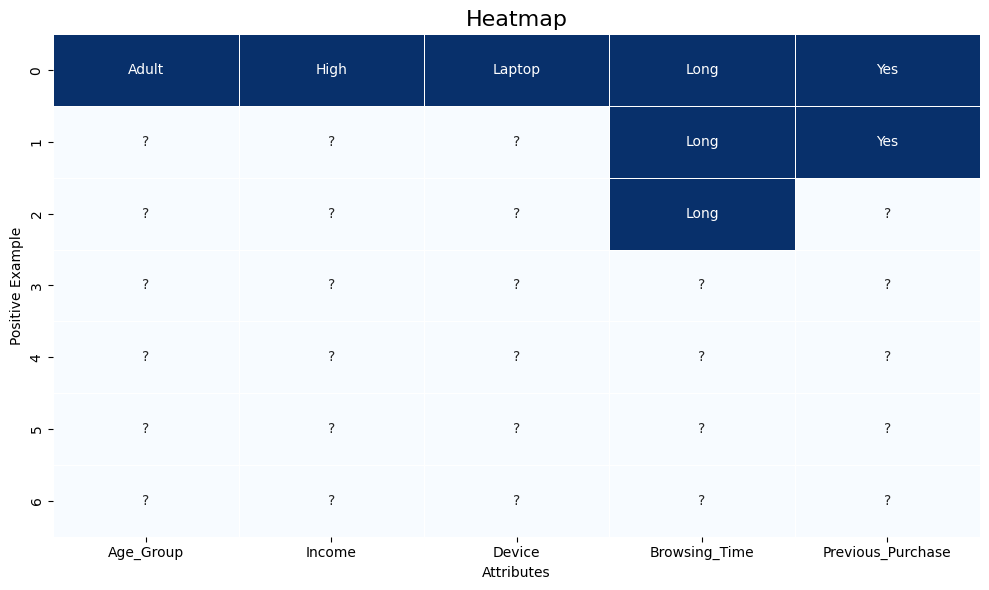

In [ ]:
history_df = pd.DataFrame(
    history,
    columns=attributes
)

# Convert:
# 1 = specific
# 0 = ?
history_numeric = history_df.applymap(
    lambda x: 0 if x == "?" else 1
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    history_numeric,
    annot=history_df,
    fmt="",
    cmap="Blues",
    cbar=False,
    linewidths=0.5
)

plt.title(
    "Heatmap",
    fontsize=16
)

plt.xlabel("Attributes")
plt.ylabel("Positive Example")

plt.tight_layout()
plt.show()



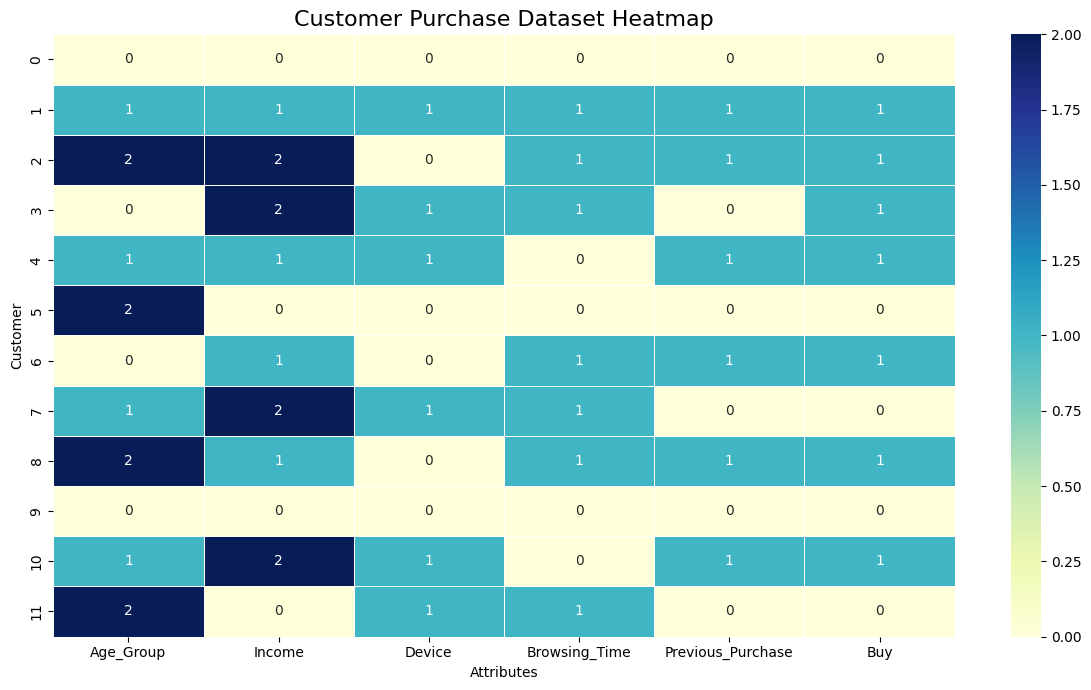

In [ ]:
# Convert categorical values into numerical values
encoded_df = df.copy()

for column in encoded_df.columns:

    encoded_df[column] = pd.factorize(
        encoded_df[column]
    )[0]

plt.figure(figsize=(12, 7))

sns.heatmap(
    encoded_df,
    annot=True,
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title(
    "Customer Purchase Dataset Heatmap",
    fontsize=16
)

plt.xlabel("Attributes")
plt.ylabel("Customer")

plt.tight_layout()
plt.show()